# 4. Modelado con scikit-learn

En este capítulo entrenamos en scikit-learn el MLP y las dos líneas base sobre muestras escalonadas de la ventana de entrenamiento. Ajustamos los hiperparámetros con búsqueda bayesiana y validación temporal, comparamos las cinco estrategias de codificación (P2) y construimos las curvas de aprendizaje y de costo que alimentan la pregunta P1. Las corridas se ejecutan con `python -m src.runner sklearn`; este capítulo lee sus resultados de `results/runs/sklearn/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

from src import sk_models as S
enc_runs = R.runs("scikit-learn", "encoding")
base_runs = R.runs("scikit-learn", "baselines")
scale_runs = R.runs("scikit-learn", "scale", include_skipped=True)
print(f"Corridas: codificación {len(enc_runs)}, líneas base {len(base_runs)}, escalado {len(scale_runs)}")

Resultados: results | prueba de humo: False


C:\Users\User\Documents\GitHub\Tareas-Deep-Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Corridas: codificación 25, líneas base 15, escalado 19


## 4.1 Modelos

| Modelo | Implementación | Entrada | Rasgos principales |
|---|---|---|---|
| Regresión logística | `SGDClassifier(loss="log_loss", penalty="l2")` | Hashing $2^{14}$ y frecuencia | Modelo lineal en la entrada codificada; descenso de gradiente estocástico |
| Árboles potenciados | `HistGradientBoostingClassifier` | Frecuencia (densa) | Suma de árboles sobre histogramas; captura interacciones y no linealidades |
| MLP | `MLPClassifier(activation="relu", solver="adam", early_stopping=True)` | Las cinco codificaciones | Capas ocultas densas, penalización $L_2$ ($\alpha$) y parada temprana |

`HistGradientBoostingClassifier` no acepta matrices dispersas, por lo que solo lo entrenamos con la codificación por frecuencia.

Para la pregunta P1 usamos además dos modelos equivalentes a los de Spark: `LogisticRegression(solver="lbfgs")` y `MLPClassifier(activation="logistic", solver="lbfgs")` con una capa oculta de 100 neuronas, sin penalización y con hashing $2^{12}$. Comparten arquitectura, activación y optimizador con `LogisticRegression` y `MultilayerPerceptronClassifier` de Spark.

**Relación entre el MLP y la regresión logística.** La última capa del MLP es una regresión logística sobre las activaciones de la última capa oculta:

$$P(y = 1 \mid x) = \sigma\big(w^\top a^{(L)}(x) + b\big).$$

Con $L = 0$ capas ocultas, $a^{(0)} = \phi_e(x)$ y el MLP se reduce a la regresión logística sobre la entrada codificada. La pregunta P3 mide cuánto aportan las capas ocultas, es decir, la representación aprendida $a^{(L)}$.

## 4.2 Búsqueda bayesiana de hiperparámetros con Optuna

`GridSearchCV` con particiones aleatorias mezclaría impresiones de días distintos entre ajuste y evaluación, y elegiría hiperparámetros con una estimación optimista. Usamos Optuna (Akiba et al., 2019) con el muestreador TPE (*Tree-structured Parzen Estimator*): en cada intento propone hiperparámetros a partir de los intentos anteriores, entrena con una muestra de entrenamiento y evalúa el ROC AUC en la muestra de validación del día 29.

Espacio de búsqueda del MLP:

| Hiperparámetro | Valores |
|---|---|
| `hidden_layer_sizes` | (50,), (100,), (100, 50), (256, 128) |
| `alpha` | $10^{-5}$ a $10^{-1}$, escala logarítmica |
| `learning_rate_init` | $10^{-4}$ a $10^{-2}$, escala logarítmica |
| `batch_size` | 256, 512, 1024, 2048 |
| `max_iter` | Controlado por la parada temprana |

La búsqueda del MLP usa hashing $2^{14}$ y los mejores hiperparámetros se aplican a las cinco codificaciones. Así, las diferencias entre codificaciones no se confunden con diferencias de ajuste.

,AUC validación,hidden_layer_sizes,alpha,learning_rate_init,batch_size,n_iter,fit_s
intento,,,,,,,
12,0.7395,256-128,1.4392e-03,0.0003,256,8,1104.8598
28,0.7394,256-128,5.1211e-04,0.0004,256,8,1092.4000
29,0.7393,256-128,8.6402e-04,0.0003,256,8,1092.1814
22,0.7392,256-128,2.9949e-04,0.0002,256,8,1089.3218
8,0.7392,256-128,3.8032e-04,0.0005,256,8,1104.5993
19,0.7390,256-128,1.9667e-04,0.0003,256,8,1089.6871
20,0.7388,256-128,9.2332e-03,0.0004,512,8,567.9552
17,0.7388,256-128,3.3787e-05,0.0005,256,8,1091.0215
23,0.7388,256-128,3.1897e-05,0.0003,256,8,1078.2950


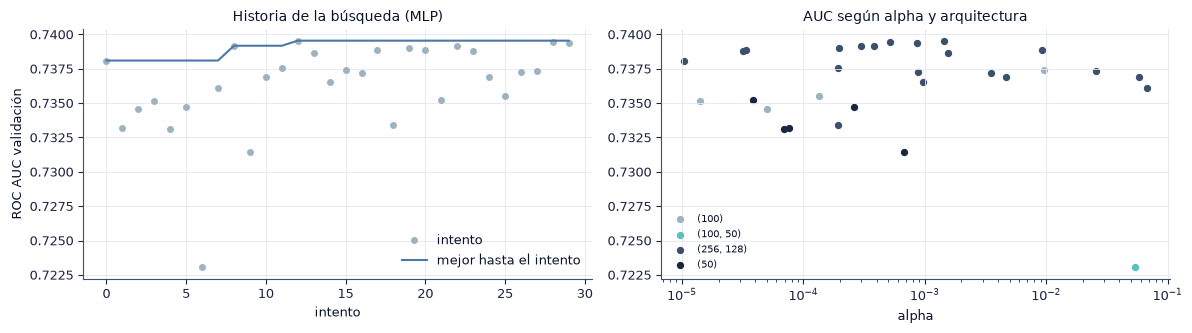

,codificación,intentos,AUC validación,mejores hiperparámetros
modelo,,,,
Regresión logística,Hashing 2^14,15,0.7364,alpha=2e-05
Regresión logística,Frecuencia,15,0.6832,alpha=4.25e-05
Gradient boosting,Frecuencia,15,0.7325,"learning_rate=0.125, max_leaf_nodes=57, min_samples_leaf=954, l2_regularization=0.00022"


In [2]:
opt = load_json(C.COMMON / f"optuna_mlp_{C.MLP_TUNE_ENCODING}.json")
trials = pd.read_csv(C.COMMON / f"optuna_mlp_{C.MLP_TUNE_ENCODING}_trials.csv")
trials = trials.rename(columns=lambda s: s.replace("params_", "").replace("user_attrs_", ""))
cols = ["number", "value", "hidden_layer_sizes", "alpha", "learning_rate_init", "batch_size", "n_iter", "fit_s"]
display(trials[cols].sort_values("value", ascending=False).head(10).rename(columns={"number": "intento", "value": "AUC validación"}).set_index("intento"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(trials["number"], trials["value"], "o", ms=4, color="#9DB4C0", label="intento")
axes[0].plot(trials["number"], trials["value"].cummax(), color=C.BAR, label="mejor hasta el intento")
axes[0].set_xlabel("intento"); axes[0].set_ylabel("ROC AUC validación"); axes[0].set_title("Historia de la búsqueda (MLP)"); axes[0].legend()
arch = sorted(trials["hidden_layer_sizes"].astype(str).unique())
pal = dict(zip(arch, ["#9DB4C0", "#5BC0BE", "#3A506B", "#1C2541"]))
for a in arch:
    t = trials[trials["hidden_layer_sizes"].astype(str) == a]
    axes[1].scatter(t["alpha"], t["value"], s=18, color=pal[a], label=f"({a.replace('-', ', ')})")
axes[1].set_xscale("log"); axes[1].set_xlabel("alpha"); axes[1].set_title("AUC según alpha y arquitectura"); axes[1].legend(fontsize=7)
fig.tight_layout(); P.save(fig, "4_2_optuna"); plt.show()

bl = []
for kind, enc in [("lr", C.MLP_TUNE_ENCODING), ("lr", "freq"), ("hgb", "freq")]:
    b = load_json(C.COMMON / f"optuna_{kind}_{enc}.json")
    bl.append({"modelo": C.MODEL_NAMES[kind], "codificación": C.ENCODING_LABELS[enc], "intentos": b["n_trials"],
               "AUC validación": round(b["best_value"], 4), "mejores hiperparámetros": ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in b["best_params"].items())})
display(pd.DataFrame(bl).set_index("modelo"))

In [3]:
bp = opt["best_params"]
R.findings(
    f"Con {opt['n_trials']} intentos, la mejor configuración del MLP usa capas ocultas ({bp['hidden_layer_sizes'].replace('-', ', ')}), "
    f"$\\alpha$ = {bp['alpha']:.2g}, tasa de aprendizaje inicial {bp['learning_rate_init']:.2g} y lotes de {bp['batch_size']}, "
    f"con un ROC AUC de validación de {opt['best_value']:.4f}. Los cinco mejores intentos difieren en "
    f"{trials['value'].nlargest(5).max() - trials['value'].nlargest(5).min():.4f} de AUC.",
    {"Preprocesamiento": "la búsqueda usa una muestra de entrenamiento de " + R.num(opt["n_train"]) + " filas y la validación del día 29, con el preprocesamiento ajustado solo con esa muestra.",
     "Modelado": "fijamos estos hiperparámetros para todas las codificaciones y semillas del MLP.",
     "Riesgos": "la búsqueda usa una sola semilla; parte de la diferencia entre los mejores intentos puede ser variación aleatoria y no una diferencia real entre configuraciones."})

### Hallazgos y decisiones

Con 30 intentos, la mejor configuración del MLP usa capas ocultas (256, 128), $\alpha$ = 0.0014, tasa de aprendizaje inicial 0.00026 y lotes de 256, con un ROC AUC de validación de 0.7395. Los cinco mejores intentos difieren en 0.0004 de AUC.

- **Preprocesamiento:** la búsqueda usa una muestra de entrenamiento de 500 000 filas y la validación del día 29, con el preprocesamiento ajustado solo con esa muestra.
- **Modelado:** fijamos estos hiperparámetros para todas las codificaciones y semillas del MLP.
- **Riesgos:** la búsqueda usa una sola semilla; parte de la diferencia entre los mejores intentos puede ser variación aleatoria y no una diferencia real entre configuraciones.


## 4.3 Parada temprana y curvas de entrenamiento

Con `early_stopping=True`, `MLPClassifier` separa al azar el 10 % de las filas de entrenamiento, evalúa la **accuracy** en ellas después de cada época y se detiene cuando no mejora durante 5 épocas. Este criterio tiene dos limitaciones en nuestro problema:

- la partición interna es aleatoria y no temporal, por lo que la validación interna es más parecida al entrenamiento que el día 29;
- con una tasa base cercana al 17 %, la accuracy cambia poco aunque mejore la probabilidad estimada, y puede detener el entrenamiento antes de que el log loss deje de bajar.

Las curvas muestran la pérdida de entrenamiento y la accuracy de la validación interna por época, para las cinco semillas del MLP con la codificación elegida en validación.

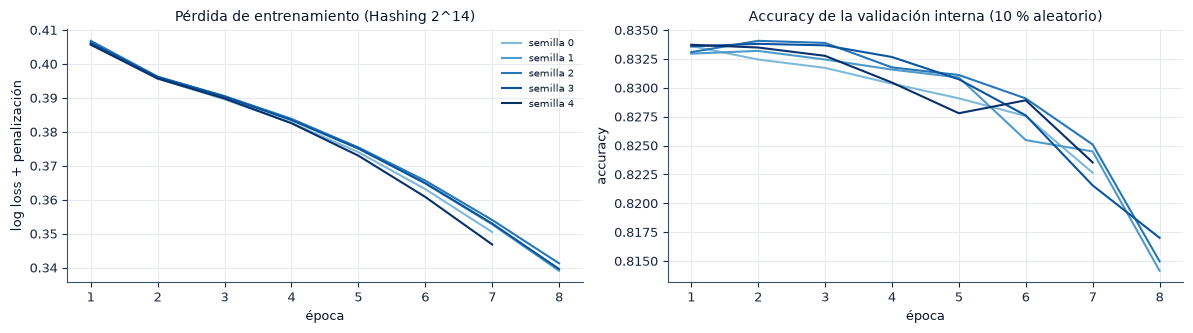

,épocas,entrenamiento (s),AUC validación,AUC prueba
semilla,,,,
0,7,2093.5313,0.7425,0.7328
1,8,2411.3356,0.7433,0.7301
2,8,2475.1503,0.7431,0.7299
3,8,2467.6525,0.7435,0.7319
4,7,2154.3010,0.7422,0.7328


In [4]:
best_enc = enc_runs.groupby("encoding")["val.roc_auc"].mean().idxmax()
g = enc_runs[enc_runs["encoding"] == best_enc].sort_values("seed")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
pal = plt.cm.Blues(np.linspace(0.45, 1, len(g)))
for cc, (_, r) in zip(pal, g.iterrows()):
    axes[0].plot(np.arange(1, len(r["loss_curve"]) + 1), r["loss_curve"], color=cc, label=f"semilla {r['seed']}")
    axes[1].plot(np.arange(1, len(r["val_curve"]) + 1), r["val_curve"], color=cc)
axes[0].set_xlabel("época"); axes[0].set_ylabel("log loss + penalización"); axes[0].set_title(f"Pérdida de entrenamiento ({C.ENCODING_LABELS[best_enc]})")
axes[1].set_xlabel("época"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy de la validación interna (10 % aleatorio)")
axes[0].legend(fontsize=7)
fig.tight_layout(); P.save(fig, "4_3_curvas_mlp"); plt.show()
display(g[["seed", "n_iter", "bench.fit_s", "val.roc_auc", "test.roc_auc"]].rename(columns={"seed": "semilla", "n_iter": "épocas", "bench.fit_s": "entrenamiento (s)", "val.roc_auc": "AUC validación", "test.roc_auc": "AUC prueba"}).set_index("semilla").round(4))

In [5]:
acc_rng = np.mean([max(v) - min(v) for v in g["val_curve"] if len(v)])
R.findings(
    f"El MLP se detiene entre {g['n_iter'].min()} y {g['n_iter'].max()} épocas según la semilla. La accuracy de la validación interna "
    f"cambia en promedio {acc_rng:.4f} a lo largo del entrenamiento, mientras la pérdida sigue bajando, lo que confirma que la accuracy es un criterio poco sensible para detener el entrenamiento en este problema.",
    {"Preprocesamiento": "la validación interna sale de la misma ventana de entrenamiento y del mismo preprocesamiento.",
     "Modelado": "mantenemos el criterio de `MLPClassifier` porque lo pide la guía; una parada temprana con log loss en el día 29 requeriría un bucle propio con `partial_fit`.",
     "Riesgos": "la detención por accuracy puede dejar al MLP subentrenado o sobreentrenado respecto del log loss; la calibración del capítulo 6 lo refleja."})

### Hallazgos y decisiones

El MLP se detiene entre 7 y 8 épocas según la semilla. La accuracy de la validación interna cambia en promedio 0.0152 a lo largo del entrenamiento, mientras la pérdida sigue bajando, lo que confirma que la accuracy es un criterio poco sensible para detener el entrenamiento en este problema.

- **Preprocesamiento:** la validación interna sale de la misma ventana de entrenamiento y del mismo preprocesamiento.
- **Modelado:** mantenemos el criterio de `MLPClassifier` porque lo pide la guía; una parada temprana con log loss en el día 29 requeriría un bucle propio con `partial_fit`.
- **Riesgos:** la detención por accuracy puede dejar al MLP subentrenado o sobreentrenado respecto del log loss; la calibración del capítulo 6 lo refleja.


## 4.4 Efecto de la codificación (P2)

Entrenamos el MLP con los mismos hiperparámetros y las cinco codificaciones, con cinco semillas cada una, sobre la muestra principal. La tabla reporta media ± desviación estándar entre semillas e intervalo de confianza del 95 % basado en la distribución $t$ de Student. La memoria es la de la matriz de entrenamiento; la memoria pico es la del proceso durante el ajuste.

C:\Users\User\Documents\GitHub\Tareas-Deep-Learning\src\report.py:61: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for key, g in df.groupby(by, sort=False):


,semillas,AUC validación,ROC AUC,Log loss,ECE,entrenamiento (s),preprocesamiento (s),matriz (MB),memoria pico (MB),dimensión
codificación,,,,,,,,,,
Hashing 2^12,5,"0.7403 ± 0.0016 [0.7383, 0.7423]","0.7293 ± 0.0020 [0.7268, 0.7317]","0.4060 ± 0.0007 [0.4051, 0.4069]","0.0097 ± 0.0054 [0.0030, 0.0164]",714.8,0.9,186.8,5711.0,4096
Hashing 2^14,5,"0.7429 ± 0.0005 [0.7423, 0.7436]","0.7315 ± 0.0014 [0.7297, 0.7333]","0.4055 ± 0.0005 [0.4048, 0.4062]","0.0117 ± 0.0024 [0.0087, 0.0147]",2320.4,0.7,186.9,6903.0,16384
Hashing 2^16,5,"0.7420 ± 0.0018 [0.7398, 0.7442]","0.7300 ± 0.0019 [0.7277, 0.7323]","0.4070 ± 0.0020 [0.4046, 0.4094]","0.0182 ± 0.0107 [0.0050, 0.0314]",9072.1,0.8,186.9,7043.0,65536
Frecuencia,5,"0.7059 ± 0.0012 [0.7043, 0.7074]","0.6632 ± 0.0121 [0.6482, 0.6783]","0.4320 ± 0.0042 [0.4268, 0.4373]","0.0286 ± 0.0100 [0.0162, 0.0411]",333.0,5.8,923.2,10750.0,242
Target encoding OOF,5,"0.7366 ± 0.0012 [0.7351, 0.7381]","0.7256 ± 0.0033 [0.7216, 0.7297]","0.4084 ± 0.0016 [0.4064, 0.4104]","0.0136 ± 0.0047 [0.0078, 0.0195]",310.3,11.3,923.2,10807.0,242


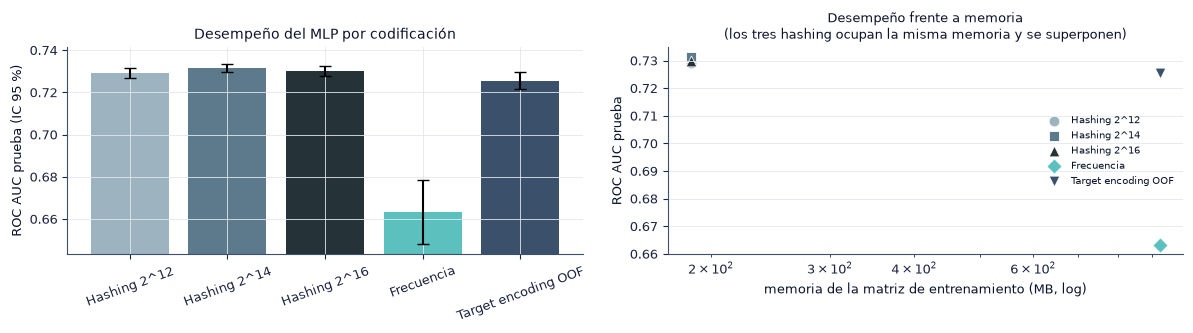

In [6]:
mets = ["val.roc_auc", "test.roc_auc", "test.log_loss", "test.ece", "bench.fit_s", "bench.prep_s", "bench.matrix_mb", "bench.fit_peak_mb", "bench.n_features"]
summ = R.summarize(enc_runs.assign(encoding=pd.Categorical(enc_runs["encoding"], C.ENCODINGS, ordered=True)).sort_values("encoding"), ["encoding"], mets)
tab = R.pretty(summ, ["encoding"], ["val.roc_auc", "test.roc_auc", "test.log_loss", "test.ece"])
tab["entrenamiento (s)"] = summ["bench.fit_s|media"].round(1).values
tab["preprocesamiento (s)"] = summ["bench.prep_s|media"].round(1).values
tab["matriz (MB)"] = summ["bench.matrix_mb|media"].round(1).values
tab["memoria pico (MB)"] = summ["bench.fit_peak_mb|media"].round(0).values
tab["dimensión"] = summ["bench.n_features|media"].astype(int).values
tab["encoding"] = tab["encoding"].map(C.ENCODING_LABELS)
display(tab.rename(columns={"encoding": "codificación", "val.roc_auc": "AUC validación"}).set_index("codificación"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
lab = [C.ENCODING_LABELS[e] for e in summ["encoding"]]
m, lo, hi = summ["test.roc_auc|media"], summ["test.roc_auc|lo"], summ["test.roc_auc|hi"]
axes[0].bar(lab, m, color=[C.ENCODING_COLORS[e] for e in summ["encoding"]], yerr=[m - lo, hi - m], capsize=4)
axes[0].set_ylim(m.min() - 0.02, m.max() + 0.01); axes[0].set_ylabel("ROC AUC prueba (IC 95 %)"); axes[0].set_title("Desempeño del MLP por codificación")
axes[0].tick_params(axis="x", rotation=20)
for (x, y, l, e), mk in zip(zip(summ["bench.matrix_mb|media"], m, lab, summ["encoding"]), ["o", "s", "^", "D", "v"]):
    axes[1].scatter(x, y, s=60, marker=mk, color=C.ENCODING_COLORS[e], label=l, edgecolor="white", linewidth=0.6)
axes[1].legend(fontsize=7, loc="center right")
axes[1].set_xscale("log"); axes[1].set_xlabel("memoria de la matriz de entrenamiento (MB, log)"); axes[1].set_ylabel("ROC AUC prueba")
axes[1].set_title("Desempeño frente a memoria\n(los tres hashing ocupan la misma memoria y se superponen)", fontsize=9)
fig.tight_layout(); P.save(fig, "4_4_codificacion"); plt.show()

Para H2 comparamos hashing $2^{14}$ y frecuencia con las diferencias pareadas por semilla. Declaramos equivalencia práctica si el intervalo de confianza del 95 % de la diferencia queda dentro de $[-\delta, \delta]$.

In [7]:
from src.metrics import paired_t
piv = enc_runs.pivot(index="seed", columns="encoding", values="test.roc_auc")
pares = []
for a in ["hash_12", "hash_14", "hash_16", "target"]:
    if a in piv and "freq" in piv:
        t = paired_t(piv[a].values, piv["freq"].values)
        pares.append({"comparación": f"{C.ENCODING_LABELS[a]} − Frecuencia", "diferencia media": t["diff"], "IC inf": t.get("lo"),
                      "IC sup": t.get("hi"), "p (t pareada)": t["p"],
                      "equivalente (IC ⊂ ±δ)": bool(t.get("lo", np.nan) > -C.DELTA_AUC and t.get("hi", np.nan) < C.DELTA_AUC)})
pares = pd.DataFrame(pares).set_index("comparación")
display(pares.round(4))
mem = summ.set_index("encoding")["bench.matrix_mb|media"]
ratio = mem["hash_14"] / mem["freq"]

,diferencia media,IC inf,IC sup,p (t pareada),equivalente (IC ⊂ ±δ)
comparación,,,,,
Hashing 2^12 − Frecuencia,0.0660,0.0500,0.0821,0.0003,False
Hashing 2^14 − Frecuencia,0.0682,0.0519,0.0846,0.0003,False
Hashing 2^16 − Frecuencia,0.0668,0.0537,0.0798,0.0001,False
Target encoding OOF − Frecuencia,0.0624,0.0468,0.0780,0.0004,False


In [8]:
h = pares.loc[f"{C.ENCODING_LABELS['hash_14']} − Frecuencia"]
best_test = summ.loc[summ["test.roc_auc|media"].idxmax(), "encoding"]
R.findings(
    f"La codificación con mayor AUC de validación es **{C.ENCODING_LABELS[best_enc]}**, y en prueba la mejor es {C.ENCODING_LABELS[best_test]}. "
    f"El hashing $2^{{14}}$ difiere de la frecuencia en {h['diferencia media']:+.4f} de AUC (IC 95 % [{h['IC inf']:.4f}, {h['IC sup']:.4f}]) "
    f"y usa {ratio:.2f} veces la memoria de la matriz de frecuencia. "
    + ("La diferencia queda dentro de ±δ, por lo que ambas codificaciones son equivalentes en la práctica." if h["equivalente (IC ⊂ ±δ)"] else
       "El intervalo no queda dentro de ±δ, por lo que no podemos declarar equivalencia práctica.")
    + (" La matriz de hashing ocupa menos memoria que la de frecuencia." if ratio < 1 else " En esta muestra la matriz dispersa de hashing no ocupa menos memoria que la densa de frecuencia, contra lo que supone H2."),
    {"Preprocesamiento": f"para las ablaciones y la interpretabilidad usamos la codificación elegida en validación ({C.ENCODING_LABELS[best_enc]}).",
     "Modelado": "la dimensión del hashing cambia la capacidad de la primera capa más que la memoria de la entrada: con una matriz dispersa, el costo dominante son los pesos $d \\times h$.",
     "Riesgos": "la comparación de memoria depende de la representación: la matriz de frecuencia es densa por el one-hot de baja cardinalidad; una representación dispersa de esas columnas la reduciría."})

### Hallazgos y decisiones

La codificación con mayor AUC de validación es **Hashing 2^14**, y en prueba la mejor es Hashing 2^14. El hashing $2^{14}$ difiere de la frecuencia en +0.0682 de AUC (IC 95 % [0.0519, 0.0846]) y usa 0.20 veces la memoria de la matriz de frecuencia. El intervalo no queda dentro de ±δ, por lo que no podemos declarar equivalencia práctica. La matriz de hashing ocupa menos memoria que la de frecuencia.

- **Preprocesamiento:** para las ablaciones y la interpretabilidad usamos la codificación elegida en validación (Hashing 2^14).
- **Modelado:** la dimensión del hashing cambia la capacidad de la primera capa más que la memoria de la entrada: con una matriz dispersa, el costo dominante son los pesos $d \times h$.
- **Riesgos:** la comparación de memoria depende de la representación: la matriz de frecuencia es densa por el one-hot de baja cardinalidad; una representación dispersa de esas columnas la reduciría.


## 4.5 Líneas base

Las líneas base usan sus propios hiperparámetros, elegidos con Optuna en la misma validación temporal. El capítulo 6 compara sus resultados con el MLP mediante pruebas estadísticas.

In [9]:
mlp_ref = enc_runs[enc_runs["encoding"].isin([C.MLP_TUNE_ENCODING, "freq"])]
comp = pd.concat([base_runs, mlp_ref])
comp["modelo"] = comp.apply(R.label, axis=1)
sb = R.summarize(comp, ["modelo"], ["val.roc_auc", "test.roc_auc", "test.pr_auc", "test.log_loss", "bench.fit_s"])
tb = R.pretty(sb, ["modelo"], ["val.roc_auc", "test.roc_auc", "test.pr_auc", "test.log_loss"])
tb["entrenamiento (s)"] = sb["bench.fit_s|media"].round(1).values
display(tb.rename(columns={"val.roc_auc": "AUC validación"}).set_index("modelo"))

,semillas,AUC validación,ROC AUC,PR AUC,Log loss,entrenamiento (s)
modelo,,,,,,
Gradient boosting · Frecuencia,5,"0.7351 ± 0.0005 [0.7346, 0.7357]","0.7246 ± 0.0011 [0.7232, 0.7260]","0.3500 ± 0.0011 [0.3487, 0.3513]","0.4085 ± 0.0005 [0.4079, 0.4091]",116.3
Regresión logística · Frecuencia,5,"0.6797 ± 0.0030 [0.6760, 0.6835]","0.6777 ± 0.0024 [0.6747, 0.6807]","0.2976 ± 0.0012 [0.2961, 0.2991]","0.4285 ± 0.0013 [0.4269, 0.4301]",16.9
Regresión logística · Hashing 2^14,5,"0.7363 ± 0.0016 [0.7343, 0.7383]","0.7273 ± 0.0019 [0.7250, 0.7296]","0.3518 ± 0.0017 [0.3496, 0.3539]","0.4084 ± 0.0019 [0.4060, 0.4107]",9.8
MLP · Frecuencia,5,"0.7059 ± 0.0012 [0.7043, 0.7074]","0.6632 ± 0.0121 [0.6482, 0.6783]","0.3036 ± 0.0115 [0.2893, 0.3179]","0.4320 ± 0.0042 [0.4268, 0.4373]",333.0
MLP · Hashing 2^14,5,"0.7429 ± 0.0005 [0.7423, 0.7436]","0.7315 ± 0.0014 [0.7297, 0.7333]","0.3606 ± 0.0013 [0.3589, 0.3622]","0.4055 ± 0.0005 [0.4048, 0.4062]",2320.4


## 4.6 Curvas de aprendizaje y de costo

Con los modelos equivalentes a los de Spark (sección 4.1) entrenamos con las muestras escalonadas. Las curvas muestran cómo cambian el AUC de prueba y el tiempo de entrenamiento con el número de filas. Un ajuste cuya duración estimada, extrapolada linealmente desde el tamaño anterior, supera el presupuesto de 90 minutos se omite y se marca como estimado.

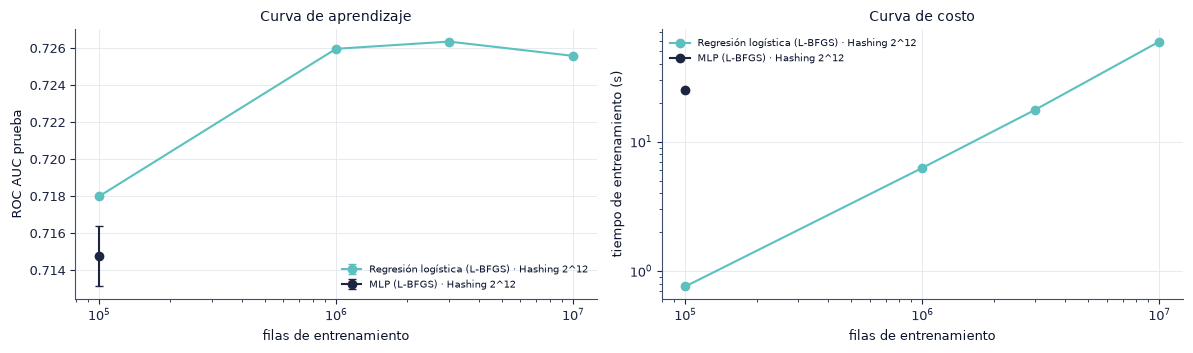

AUC prueba      DE  \
modelo                                      filas                            
Regresión logística (L-BFGS) · Hashing 2^12 1.0000e+05      0.7180  0.0000   
                                            1.0000e+06      0.7260  0.0000   
                                            3.0000e+06      0.7264  0.0000   
                                            1.0000e+07      0.7256  0.0000   
MLP (L-BFGS) · Hashing 2^12                 1.0000e+05      0.7148  0.0016   

                                                        entrenamiento (s)  \
modelo                                      filas                           
Regresión logística (L-BFGS) · Hashing 2^12 1.0000e+05             0.7595   
                                            1.0000e+06             6.2664   
                                            3.0000e+06            17.6742   
                                            1.0000e+07            59.4036   
MLP (L-BFGS) · Hashing 2^12                 1.0000e+05            24.8781   

                                                        iteraciones  
modelo                                      filas                    
Regresión logística (L-BFGS) · Hashing 2^12 1.0000e+05        100.0  
                                            1.0000e+06        100.0  
                                            3.0000e+06        100.0  
                                            1.0000e+07        100.0  
MLP (L-BFGS) · Hashing 2^12                 1.0000e+05        100.0

In [10]:
sc = scale_runs.copy()
sc["n"] = sc["n_train"].astype(float)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
rows = []
for kind, cc in [("lr_lbfgs", "#5BC0BE"), ("mlp_lbfgs", "#1C2541")]:
    g = sc[(sc["model"] == kind) & (~sc["omitido"])]
    if g.empty:
        continue
    a = g.groupby("n").agg(auc=("test.roc_auc", "mean"), auc_sd=("test.roc_auc", "std"), t=("bench.fit_s", "mean"), it=("n_iter", "mean")).reset_index()
    name = R.label({"model": kind, "encoding": C.P1_ENCODING})
    axes[0].errorbar(a["n"], a["auc"], yerr=a["auc_sd"].fillna(0), marker="o", color=cc, capsize=3, label=name)
    axes[1].plot(a["n"], a["t"], marker="o", color=cc, label=name)
    om = sc[(sc["model"] == kind) & (sc["omitido"])]
    if not om.empty:
        axes[1].scatter(om["n"], om["fit_s_estimado"], marker="o", facecolors="none", edgecolors=cc, label=f"{name} (estimado, omitido)")
    rows.append(a.assign(modelo=name))
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("filas de entrenamiento")
axes[0].set_ylabel("ROC AUC prueba"); axes[0].set_title("Curva de aprendizaje"); axes[0].legend(fontsize=7)
axes[1].set_yscale("log"); axes[1].set_ylabel("tiempo de entrenamiento (s)"); axes[1].set_title("Curva de costo"); axes[1].legend(fontsize=7)
fig.tight_layout(); P.save(fig, "4_6_aprendizaje_costo"); plt.show()
curvas = pd.concat(rows) if rows else pd.DataFrame()
display(curvas.rename(columns={"n": "filas", "auc": "AUC prueba", "auc_sd": "DE", "t": "entrenamiento (s)", "it": "iteraciones"}).set_index(["modelo", "filas"]).round(4))

In [11]:
txt = []
for name, g in curvas.groupby("modelo"):
    g = g.sort_values("n")
    if len(g) > 1:
        b = np.polyfit(np.log(g["n"]), np.log(g["t"]), 1)[0]
        txt.append(f"{name}: el AUC pasa de {g['auc'].iloc[0]:.4f} con {R.num(g['n'].iloc[0])} filas a {g['auc'].iloc[-1]:.4f} con "
                   f"{R.num(g['n'].iloc[-1])}, y el tiempo crece como $n^{{{b:.2f}}}$")
bs = [float(t.split("$n^{")[1].split("}")[0]) for t in txt]
R.findings(
    "; ".join(txt) + ". " + ("Un exponente cercano a 1 indica un costo lineal en el número de filas, lo esperable con un número fijo de iteraciones de L-BFGS."
                             if bs and min(bs) > 0.85 else
                             "Un exponente menor que 1 indica que parte del costo es fijo (inicialización, número de iteraciones hasta converger) y pesa más en las muestras pequeñas."),
    {"Preprocesamiento": "las muestras están anidadas, por lo que cada punto de la curva añade filas a las del punto anterior.",
     "Modelado": "la curva de aprendizaje indica si más datos mejoran el modelo; si se aplana, aumentar el volumen solo aumenta el costo.",
     "Riesgos": "con tres semillas en los tamaños grandes, la variación del tiempo entre corridas es una fuente de incertidumbre en el punto de cruce del capítulo 7."})

### Hallazgos y decisiones

Regresión logística (L-BFGS) · Hashing 2^12: el AUC pasa de 0.7180 con 100 000 filas a 0.7256 con 10 000 000, y el tiempo crece como $n^{0.94}$. Un exponente cercano a 1 indica un costo lineal en el número de filas, lo esperable con un número fijo de iteraciones de L-BFGS.

- **Preprocesamiento:** las muestras están anidadas, por lo que cada punto de la curva añade filas a las del punto anterior.
- **Modelado:** la curva de aprendizaje indica si más datos mejoran el modelo; si se aplana, aumentar el volumen solo aumenta el costo.
- **Riesgos:** con tres semillas en los tamaños grandes, la variación del tiempo entre corridas es una fuente de incertidumbre en el punto de cruce del capítulo 7.
